## 1. Basic Well Log Visualization with Matplotlib

#### Keith R. Holdaway FGS

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def visualize_well_logs():
    # Load sample well log data
    data = {
        'Depth': np.arange(1000, 1100, 0.5),
        'GR': np.random.normal(50, 15, 200),
        'RT': np.random.lognormal(2, 0.3, 200),
        'NPHI': np.random.uniform(0.15, 0.45, 200),
        'RHOB': np.random.uniform(2.0, 2.8, 200)
    }
    df = pd.DataFrame(data)
    
    # Create log plot
    fig, axes = plt.subplots(1, 4, figsize=(15, 10), sharey=True)
    fig.suptitle('Well Log Visualization', fontsize=16)
    
    # Gamma Ray track
    axes[0].plot(df['GR'], df['Depth'], color='green')
    axes[0].set_xlabel('GR (API)')
    axes[0].set_ylabel('Depth (m)')
    axes[0].grid(True)
    
    # Resistivity track
    axes[1].semilogx(df['RT'], df['Depth'], color='blue')
    axes[1].set_xlabel('RT (ohm-m)')
    axes[1].grid(True)
    
    # Porosity track
    axes[2].plot(df['NPHI']*100, df['Depth'], color='red', label='NPHI')
    axes[2].plot(df['RHOB'], df['Depth'], color='black', label='RHOB')
    axes[2].set_xlabel('NPHI (%) / RHOB (g/cc)')
    axes[2].legend()
    axes[2].grid(True)
    
    # Empty track for future use
    axes[3].axis('off')
    
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

visualize_well_logs()

## 2. Petrophysical Calculations with NumPy

In [ ]:
import numpy as np
import pandas as pd

def petrophysical_analysis():
    # Sample data
    depth = np.arange(3000, 3200, 0.5)
    nphi = np.random.uniform(0.1, 0.4, len(depth))
    rhob = np.random.uniform(2.0, 2.8, len(depth))
    gr = np.random.normal(60, 20, len(depth))
    rt = np.random.lognormal(2, 0.4, len(depth))
    
    # Calculate shale volume using linear GR method
    gr_clean = 30  # API
    gr_shale = 120  # API
    vsh = (gr - gr_clean) / (gr_shale - gr_clean)
    vsh = np.clip(vsh, 0, 1)  # Ensure between 0-1
    
    # Calculate porosity (simplified)
    phi = (nphi + (2.65 - rhob)/2.65) / 2
    
    # Calculate water saturation (Archie equation - simplified)
    a, m, n = 1.0, 2.0, 2.0  # Archie parameters
    rw = 0.1  # Ohm-m @ formation temperature
    sw = ((a * rw) / (phi**m * rt)) ** (1/n)
    sw = np.clip(sw, 0.01, 1)  # Ensure between 0-1
    
    # Create DataFrame
    results = pd.DataFrame({
        'Depth': depth,
        'GR': gr,
        'RT': rt,
        'NPHI': nphi,
        'RHOB': rhob,
        'VSH': vsh,
        'PHI': phi,
        'SW': sw
    })
    
    # Print statistics
    print("\nPetrophysical Analysis Results Summary:")
    print(results.describe())
    
    return results

df = petrophysical_analysis()

## 3. Machine Learning for Lithology Classification (Scikit-learn)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler

def lithology_classification():
    # Create synthetic dataset
    np.random.seed(42)
    n_samples = 1000
    
    # Features: GR, RT, NPHI, RHOB
    data = {
        'GR': np.concatenate([
            np.random.normal(30, 5, n_samples//4),  # Sandstone
            np.random.normal(75, 15, n_samples//4),  # Shale
            np.random.normal(50, 10, n_samples//4),  # Limestone
            np.random.normal(100, 20, n_samples//4)   # Coal
        ]),
        'RT': np.concatenate([
            np.random.lognormal(2.5, 0.3, n_samples//4),
            np.random.lognormal(1.8, 0.4, n_samples//4),
            np.random.lognormal(2.2, 0.3, n_samples//4),
            np.random.lognormal(3.0, 0.5, n_samples//4)
        ]),
        'NPHI': np.concatenate([
            np.random.uniform(0.25, 0.35, n_samples//4),
            np.random.uniform(0.15, 0.25, n_samples//4),
            np.random.uniform(0.20, 0.30, n_samples//4),
            np.random.uniform(0.40, 0.50, n_samples//4)
        ]),
        'RHOB': np.concatenate([
            np.random.uniform(2.3, 2.5, n_samples//4),
            np.random.uniform(2.5, 2.7, n_samples//4),
            np.random.uniform(2.4, 2.6, n_samples//4),
            np.random.uniform(1.3, 1.6, n_samples//4)
        ])
    }
    
    # Target: Lithology (0=Sandstone, 1=Shale, 2=Limestone, 3=Coal)
    target = np.concatenate([
        np.zeros(n_samples//4),
        np.ones(n_samples//4),
        np.full(n_samples//4, 2),
        np.full(n_samples//4, 3)
    ])
    
    df = pd.DataFrame(data)
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        df, target, test_size=0.3, random_state=42
    )
    
    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Train model
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train_scaled, y_train)
    
    # Evaluate
    y_pred = model.predict(X_test_scaled)
    print("\nLithology Classification Report:")
    print(classification_report(y_test, y_pred, 
                               target_names=['Sandstone', 'Shale', 'Limestone', 'Coal']))
    
    # Feature importance
    print("\nFeature Importances:")
    for name, importance in zip(df.columns, model.feature_importances_):
        print(f"{name}: {importance:.3f}")
    
    return model, scaler

model, scaler = lithology_classification()

## 4. Random Forest for Permeability Prediction (TensorFlow/Keras)

Training Random Forest model...

Permeability Prediction Results:
MSE: 0.0157
R²: 0.7628


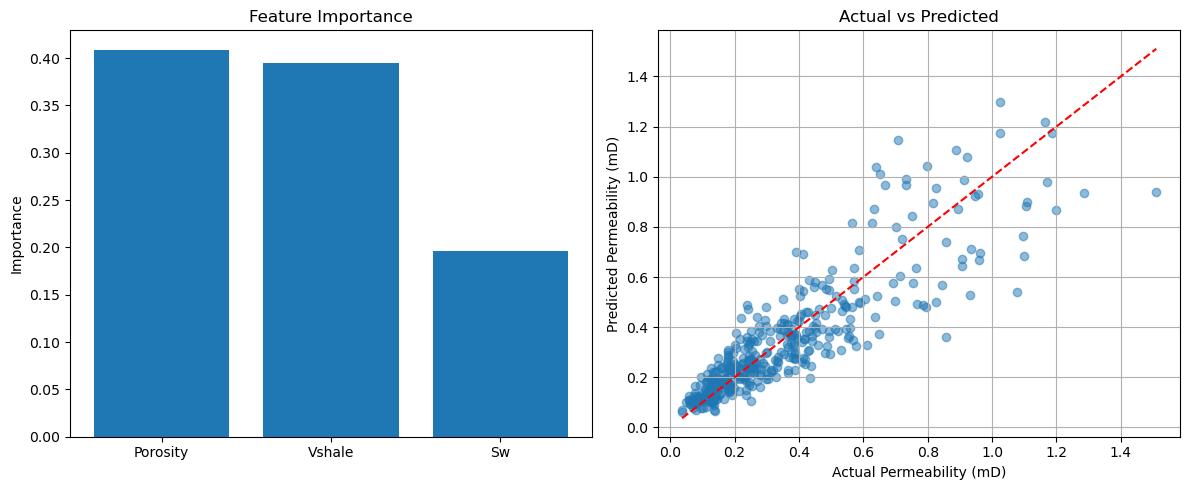

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

def permeability_prediction_sklearn():
    # Create synthetic dataset
    np.random.seed(42)
    n_samples = 2000
    
    # Features: Porosity, Vshale, Sw
    X = np.column_stack([
        np.random.uniform(0.05, 0.35, n_samples),  # Porosity
        np.random.uniform(0, 0.7, n_samples),      # Vshale
        np.random.uniform(0.2, 1.0, n_samples)     # Sw
    ])
    
    # Target: Permeability (log-normal distribution)
    log_mean = -1 + 5*X[:,0] - 2*X[:,1] - X[:,2]
    y = np.exp(np.random.normal(log_mean, 0.3))
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    
    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Use Random Forest (less memory intensive)
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    )
    
    print("Training Random Forest model...")
    model.fit(X_train_scaled, y_train)
    
    # Evaluate
    y_pred = model.predict(X_test_scaled)
    
    print("\nPermeability Prediction Results:")
    print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")
    print(f"R²: {r2_score(y_test, y_pred):.4f}")
    
    # Feature importance
    feature_names = ['Porosity', 'Vshale', 'Sw']
    importance = model.feature_importances_
    
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.bar(feature_names, importance)
    plt.title('Feature Importance')
    plt.ylabel('Importance')
    
    # Plot actual vs predicted
    plt.subplot(1, 2, 2)
    plt.scatter(y_test, y_pred, alpha=0.5)
    plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--')
    plt.xlabel('Actual Permeability (mD)')
    plt.ylabel('Predicted Permeability (mD)')
    plt.title('Actual vs Predicted')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
    return model, scaler

# Try this if TensorFlow keeps crashing
perm_model, perm_scaler = permeability_prediction_sklearn()

## 5. Time Series Analysis for Production Forecasting (Statsmodels)

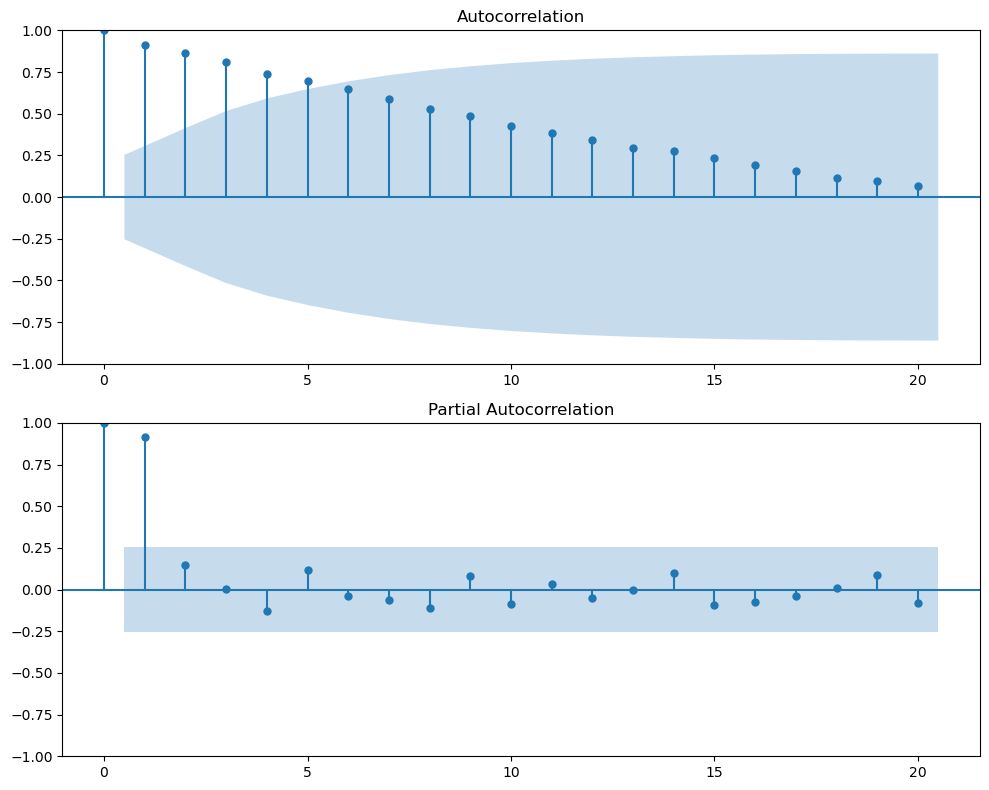

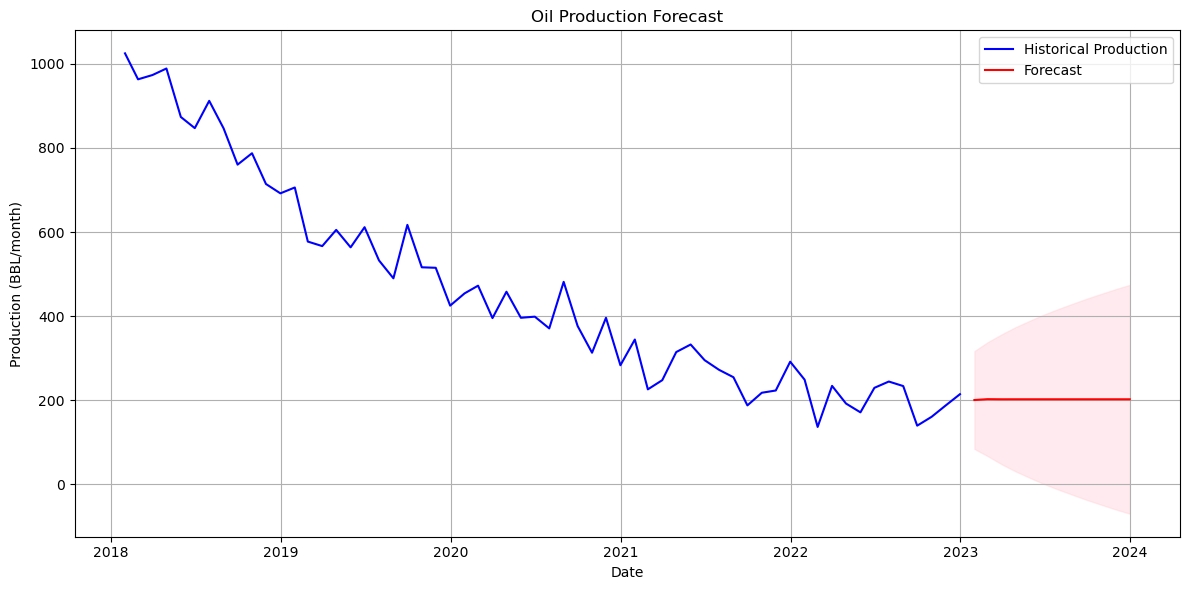


Production Forecast Summary:
              Forecast   Lower_CI    Upper_CI
2023-01-31  200.627915  84.290979  316.964852
2023-02-28  202.658667  67.644427  337.672908
2023-03-31  202.362606  47.677897  357.047316
2023-04-30  202.405769  30.727419  374.084119
2023-05-31  202.399476  15.205340  389.593612
2023-06-30  202.400393   0.889576  403.911211
2023-07-31  202.400260 -12.476553  417.277072
2023-08-31  202.400279 -25.058313  429.858871
2023-09-30  202.400276 -36.979730  441.780283
2023-10-31  202.400277 -48.334967  453.135521
2023-11-30  202.400277 -59.197770  463.998323
2023-12-31  202.400277 -69.627136  474.427689


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def production_forecasting():
    # Create synthetic production data
    np.random.seed(42)
    months = 60
    index = pd.date_range(start='2018-01-01', periods=months, freq='ME')  # Changed 'M' to 'ME'
    
    # Create declining production with noise
    decline_rate = 0.03  # 3% monthly decline
    base_production = 1000  # BBL/month
    noise = np.random.normal(0, 50, months)
    
    production = base_production * (1 - decline_rate) ** np.arange(months) + noise
    production = np.maximum(production, 50)  # Don't go below 50 BBL/month
    
    # Create DataFrame
    df = pd.DataFrame({'Production': production}, index=index)
    
    # Plot ACF and PACF to determine ARIMA parameters
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
    plot_acf(df['Production'], ax=ax1, lags=20)
    plot_pacf(df['Production'], ax=ax2, lags=20)
    plt.tight_layout()
    plt.show()
    
    # Fit ARIMA model
    model = ARIMA(df['Production'], order=(1, 1, 1))
    results = model.fit()
    
    # Forecast next 12 months
    forecast_months = 12
    forecast = results.get_forecast(steps=forecast_months)
    forecast_index = pd.date_range(start=df.index[-1] + pd.DateOffset(months=1), 
                                 periods=forecast_months, freq='ME')  # Changed 'M' to 'ME'
    
    # Create forecast DataFrame
    forecast_df = pd.DataFrame({
        'Forecast': forecast.predicted_mean,
        'Lower_CI': forecast.conf_int()['lower Production'],
        'Upper_CI': forecast.conf_int()['upper Production']
    }, index=forecast_index)
    
    # Plot results
    plt.figure(figsize=(12, 6))
    plt.plot(df.index, df['Production'], label='Historical Production', color='blue')
    plt.plot(forecast_df.index, forecast_df['Forecast'], label='Forecast', color='red')
    plt.fill_between(forecast_df.index, 
                    forecast_df['Lower_CI'], 
                    forecast_df['Upper_CI'], 
                    color='pink', alpha=0.3)
    plt.title('Oil Production Forecast')
    plt.xlabel('Date')
    plt.ylabel('Production (BBL/month)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
    # Print forecast summary
    print("\nProduction Forecast Summary:")
    print(forecast_df)
    
    return df, forecast_df

historical, forecast = production_forecasting()